# Fintech Complaint Intelligence: analysis

A payments company's complaint operations team has three recurring jobs: send each new complaint to the right
queue, notice when a new problem starts spreading, and find past cases like the one on the desk. This notebook
walks through all three on real consumer complaints about money transfers, payment apps and virtual currency,
filed with the U.S. Consumer Financial Protection Bureau (CFPB).

| Part | Question | Method | Validation |
|---|---|---|---|
| Routing | Which issue queue does a narrative belong to? | TF-IDF + logistic regression vs fine-tuned DistilBERT | temporal holdout (train 2023-24, test 2025 to May 2026), paired bootstrap |
| Emerging issues | Which topics are surging this month? | sentence-embedding topics + binomial burst test | injection-recovery of synthetic surges, comparison with the CFPB issue labels |
| Similar cases | Which past complaints look like this one? | TF-IDF, MiniLM, BGE-small (FAISS), cross-encoder rerank | same-issue precision@k against a random-retrieval baseline |
| Entities | Can an off-the-shelf NER read these texts? | spaCy `en_core_web_sm` | automatic spot check against the CFPB's own redaction and amount formatting |

Everything below reads the tables written by `scripts/run_pipeline.py`. Run metadata:

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 90)
meta = json.loads((RES / 'run_metadata.json').read_text())
meta['data'], meta['timings_s']

({'source': 'huggingface.co/datasets/vivekkopthsd/cfpb-consumer-complaints (mirror of the CFPB bulk export, as of 2026-08-11)',
  'product': 'Money transfer, virtual currency, or money service',
  'window': ['2021-01-01', '2026-05-31'],
  'complaints': 107066,
  'issues_in_window': 17,
  'near_duplicate_groups': 65494,
  'complaints_in_campaign_groups': 40029,
  'campaign_group_size': 100,
  'live_check': {'found_live': 1.0,
   'product_match': 1.0,
   'issue_match': 1.0,
   'company_match': 1.0,
   'date_match': 1.0,
   'narrative_in_live_api': 0.0,
   'n': 100}},
 {'load_s': 18.8,
  'dedup_s': 11.0,
  'live_check_s': 0.0,
  'distilbert_train_s': 0.0,
  'embed_minilm_s': 0.1,
  'injection_s': 10.3,
  'search_tfidf_s': 8.0,
  'embed_bge_s': 0.0,
  'entities_s': 11.2,
  'total_s': 203.7})

## 1. Data and a check against the live CFPB record

The CFPB's live API and bulk export no longer include the consumer narrative field (checked 2026-10-09: the
API rejects `complaint_what_happened` and the bulk CSV has no narrative column). The narratives therefore come
from a public-domain mirror of the last bulk export that still carried them (as of 2026-08-11; sha256 verified
on download). The analysis window is January 2021 to May 2026, because narratives are published with a lag
and thin out in the last months of the snapshot.

To make sure the mirror is faithful, 100 random complaint ids were looked up in the live API. Product, issue,
company and date match for all 100. As expected, none of them carry a narrative in the live API.

In [2]:
pd.read_csv(RES / 'live_api_crosscheck.csv').drop(columns='complaint_id').mean().to_frame('share of sampled complaints')

,share of sampled complaints
found_live,1.0
product_match,1.0
issue_match,1.0
company_match,1.0
date_match,1.0
narrative_in_live_api,0.0


## 2. Template campaigns and near-duplicates

Narratives were grouped with MinHash (128 permutations, word 5-shingles) and LSH; two complaints join a group
when their estimated Jaccard similarity is at least 0.5. The first table checks the MinHash estimates against
exact Jaccard on real pairs: the estimate is unbiased (mean error +0.005 within groups) and none of 800 hard
negatives (same company and month, different groups) has an exact Jaccard of 0.5 or more.

In January 2025 complaint volume jumped from about 1,100 to 41,618 a month. 82% of that month were copies of
templates: one Cash App (Block, Inc.) template was filed 26,464 times and one Zelle (Early Warning Services)
template, which cites a recent CFPB lawsuit, 12,726 times. Across January 2025 to May 2026, 54% of all
complaints belong to a template group with at least 100 members.

Every model below is trained and evaluated on one complaint per group, and a test complaint is dropped if its
group already appeared before the test period.

In [3]:
pd.read_csv(RES / 'minhash_check.csv')

,pair,n,mean_exact,mean_estimated,mean_error,sd_error,share_exact_ge_0_5,corr_all_pairs
0,"different groups, same company and month",800,7.000e-04,8.000e-04,0.000,0.003,0.000,0.998
1,same group,800,7.406e-01,7.458e-01,0.005,0.035,0.929,0.998


In [4]:
pd.read_csv(RES / 'near_duplicate_groups.csv').head(8)[['n_complaints', 'first_date', 'last_date', 'top_company', 'top_issue', 'example_start']]

,n_complaints,first_date,last_date,top_company,top_issue,example_start
0,26464,2025-01-16,2026-05-06,"Block, Inc.",Other transaction problem,"I am filing a complaint against Cash App ( Block , Inc. ) due to inadequate customer s..."
1,12726,2025-01-15,2026-04-23,"Early Warning Services, LLC",Other transaction problem,I am writing to formally express my concerns regarding Zelles handing disputes particu...
2,474,2021-02-02,2023-02-02,"Paypal Holdings, Inc","Managing, opening, or closing your mobile wallet account",paypal closed my account for no reason and will not help me with getting it back up an...
3,257,2022-07-06,2025-05-21,"Coinbase, Inc.",Fraud or scam,"Commencing on or around /2022, I fell victim to a multi-layered scam operation run by ..."
4,108,2021-01-28,2024-08-16,"Coinbase, Inc.",Fraud or scam,"Commencing on or about /2020, I fell victim to a multilayered scam operation orchestra..."
5,58,2022-09-15,2025-02-23,"Coinbase, Inc.",Fraud or scam,This is to complain against the Binance.US and Binance.com. URGENCY : HIGH IMPORTANCE ...
6,55,2025-01-15,2025-10-12,"Early Warning Services, LLC",Other transaction problem,I would like to be reimbursed for the reported transaction.
7,51,2022-05-14,2022-06-13,"Paypal Holdings, Inc","Managing, opening, or closing your mobile wallet account",I believe that it was a mistake to close my PayPal account. I am using my Paypal accou...


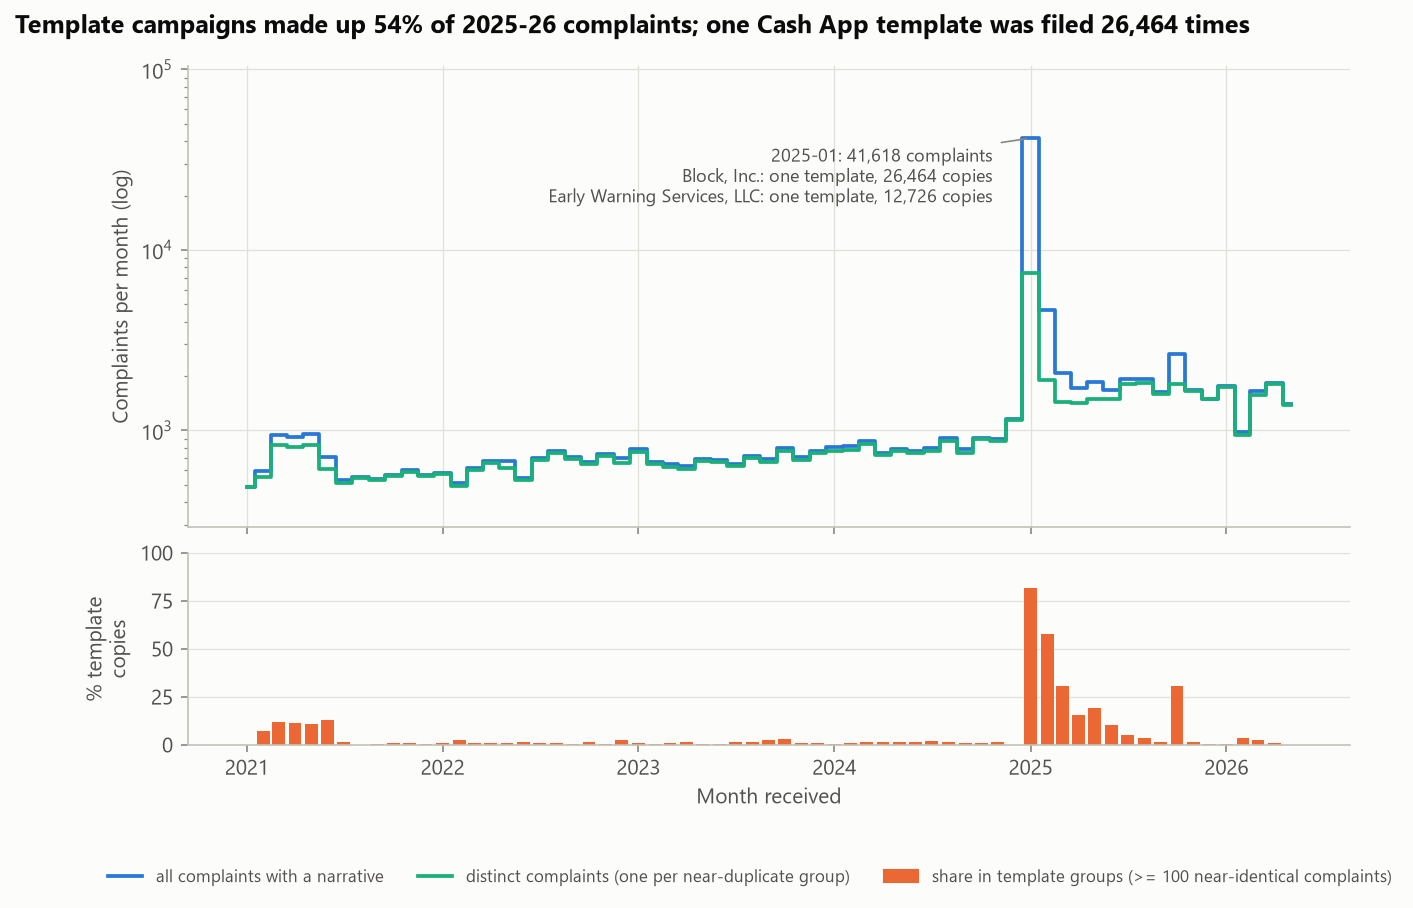

In [5]:
display(Image(FIG / '01_volume_and_campaigns.png'))

## 3. Routing: which issue queue?

The target is the CFPB `issue` the consumer selected, restricted to the 13 issues with at least 100
deduplicated training complaints (4 rare issues dropped). Models learn from 2023-2024 (the issue taxonomy is
stable from 2023), with the latest 10% (8 November to 31 December 2024) held out for tuning, and are scored on
January 2025 to May 2026.

* **TF-IDF + logistic regression wins.** Macro-F1 0.328 against 0.307 for fine-tuned DistilBERT (difference
  -0.022, 95% CI [-0.029, -0.014]); accuracy 0.442 vs 0.384. The same order holds on the validation months.
* **Absolute scores are low** because the labels are the consumer's own choice among overlapping categories:
  "Fraud or scam", "Unauthorized transactions or other transaction problem" and "Other transaction problem"
  describe the same events. Top-2 accuracy is 0.646 for TF-IDF.
* **The evaluation protocol moves the number more than the model does.** Random 5-fold CV inside 2023-24 gives
  0.373, 0.045 above the temporal test. Scoring template copies as separate complaints drops macro-F1 to 0.265 and
  accuracy to 0.219, because one misrouted template counts thousands of times.

In [6]:
routing = pd.read_csv(RES / 'routing_results.csv')
display(routing)
pd.read_csv(RES / 'routing_significance.csv')

,model,protocol,macro_f1,accuracy,top2_accuracy,n,macro_f1_sd
0,TF-IDF + LR,temporal test (deduplicated),0.328,0.442,0.646,32429,NaN
1,DistilBERT (fine-tuned),temporal test (deduplicated),0.307,0.384,0.587,32429,NaN
2,TF-IDF + LR,validation (late 2024),0.339,NaN,NaN,1771,NaN
3,DistilBERT (fine-tuned),validation (late 2024),0.320,NaN,NaN,1771,NaN
4,TF-IDF + LR,random 5-fold CV inside 2023-2024,0.373,NaN,NaN,15936,0.018
5,TF-IDF + LR,temporal test incl. template copies,0.265,0.219,NaN,72222,NaN


,comparison,metric,diff,ci_low,ci_high,p_value
0,DistilBERT - TF-IDF + LR,macro_f1,-0.022,-0.029,-0.014,5.000e-04


In [7]:
display(pd.read_csv(RES / 'routing_tfidf_tuning.csv'))
pd.read_csv(RES / 'routing_distilbert_history.csv')

,C,val_macro_f1,fit_s
0,1.0,0.335,31.370
1,4.0,0.339,44.041
2,16.0,0.326,70.713


,epoch,train_loss,val_macro_f1,train_s
0,1,2.125,0.318,87.169
1,2,1.699,0.320,85.871


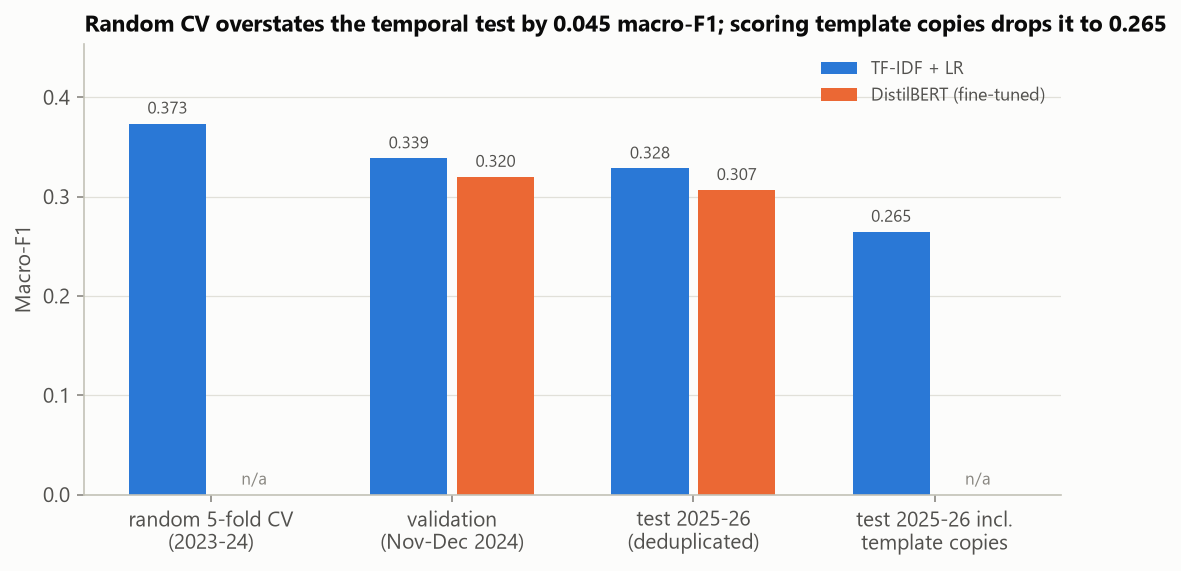

In [8]:
display(Image(FIG / '06_evaluation_protocol.png'))

### Per-issue F1 and the main confusions

TF-IDF is ahead on 9 of 13 issues. Issues with a concrete vocabulary (lost money orders, wallet access, customer
service, fraud) reach F1 0.40-0.59; vague catch-all issues ("Other service problem", "Confusing or missing
disclosures", "Misleading advertising", "Wrong amount") stay at or below 0.15 for both models.

**Is DistilBERT held back by truncation?** It reads only the first 256 tokens, and 28% of test narratives are
longer. The table below shows it trails TF-IDF by a similar margin on narratives it reads in full (0.290 vs 0.310)
and on truncated ones (0.347 vs 0.373), so truncation does not explain the gap. Two epochs on 15,936 narratives
(the low-compute budget for this project) is the more likely limit.

In [9]:
pd.read_csv(RES / 'routing_per_class.csv').sort_values('test_n', ascending=False)

,issue,train_n,test_n,f1_tfidf,f1_distilbert
2,Fraud or scam,5819,8859,0.589,0.570
7,Other transaction problem,2763,8338,0.307,0.159
10,Unauthorized transactions or other transaction problem,1649,4887,0.486,0.489
9,Trouble accessing funds in your mobile or digital wallet,1065,2844,0.508,0.507
5,Money was not available when promised,1484,2144,0.431,0.393
4,"Managing, opening, or closing your mobile wallet account",996,1355,0.408,0.443
1,Confusing or missing disclosures,501,1298,0.123,0.059
6,Other service problem,438,872,0.149,0.129
11,Unexpected or other fees,390,536,0.304,0.262
8,Problem with customer service,403,470,0.440,0.385


In [10]:
pd.read_csv(RES / 'routing_by_length.csv')

,length,n,share,macro_f1_tfidf,macro_f1_distilbert,accuracy_tfidf,accuracy_distilbert
0,<= 256 tokens (read in full),23485,0.724,0.310,0.290,0.409,0.353
1,> 256 tokens (truncated),8944,0.276,0.373,0.347,0.529,0.464


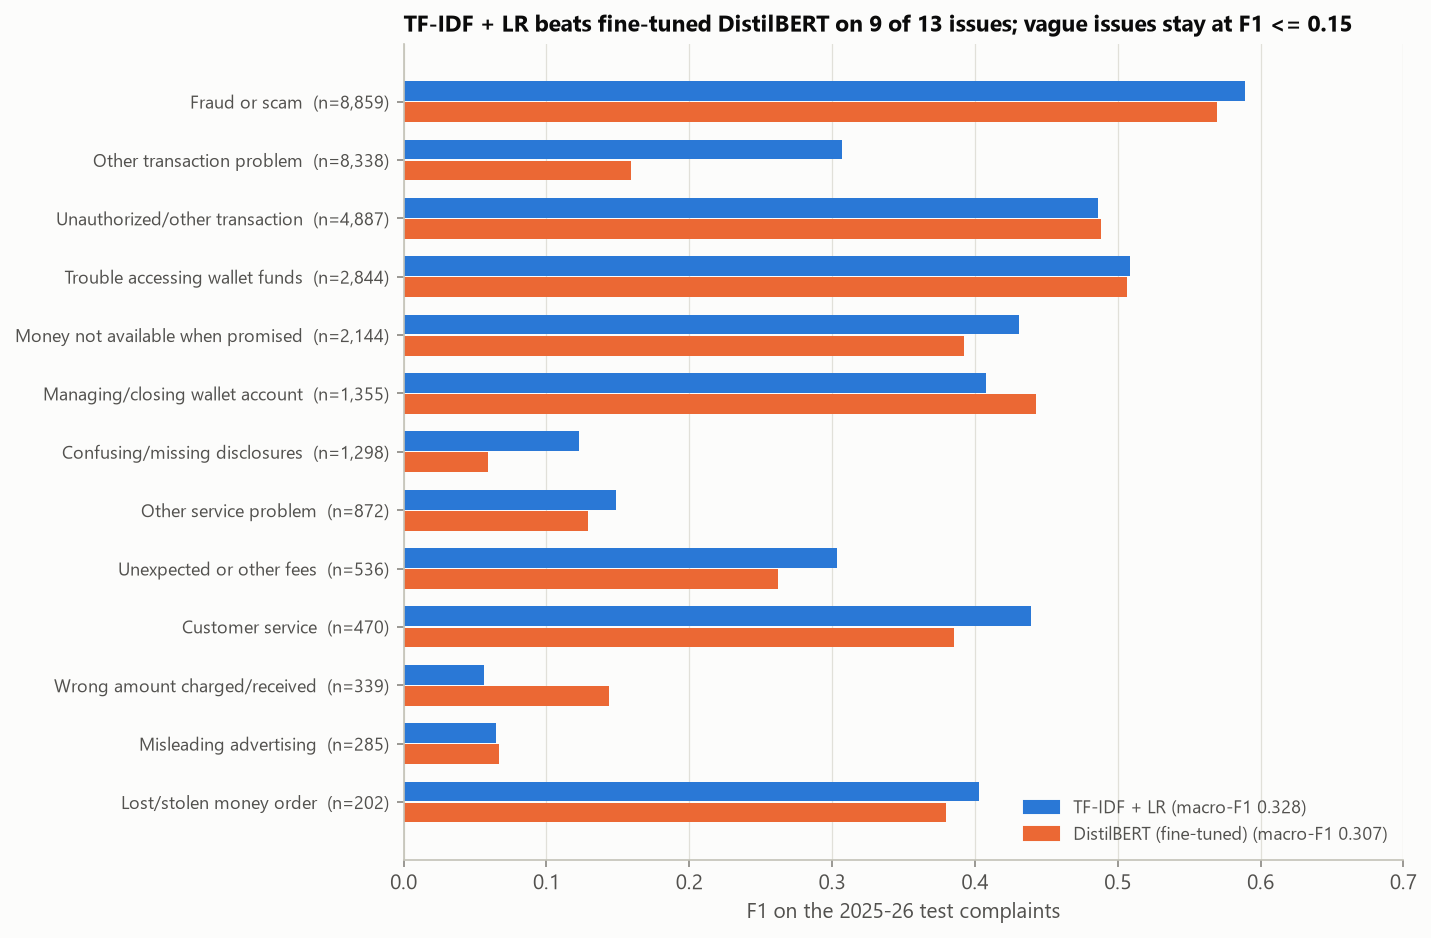

In [11]:
display(Image(FIG / '03_routing_per_issue_f1.png'))

In [12]:
pd.read_csv(RES / 'routing_top_confusions.csv')

,true,predicted,count,share_of_true,model
0,Other transaction problem,Fraud or scam,2256,0.271,TF-IDF + LR
1,Other transaction problem,Unauthorized transactions or other transaction problem,2028,0.243,TF-IDF + LR
2,Fraud or scam,Unauthorized transactions or other transaction problem,1814,0.205,TF-IDF + LR
3,Unauthorized transactions or other transaction problem,Fraud or scam,703,0.144,TF-IDF + LR
4,Fraud or scam,Other transaction problem,702,0.079,TF-IDF + LR
5,Other transaction problem,Money was not available when promised,641,0.077,TF-IDF + LR
6,Unauthorized transactions or other transaction problem,Other transaction problem,537,0.110,TF-IDF + LR
7,Money was not available when promised,Other transaction problem,420,0.196,TF-IDF + LR


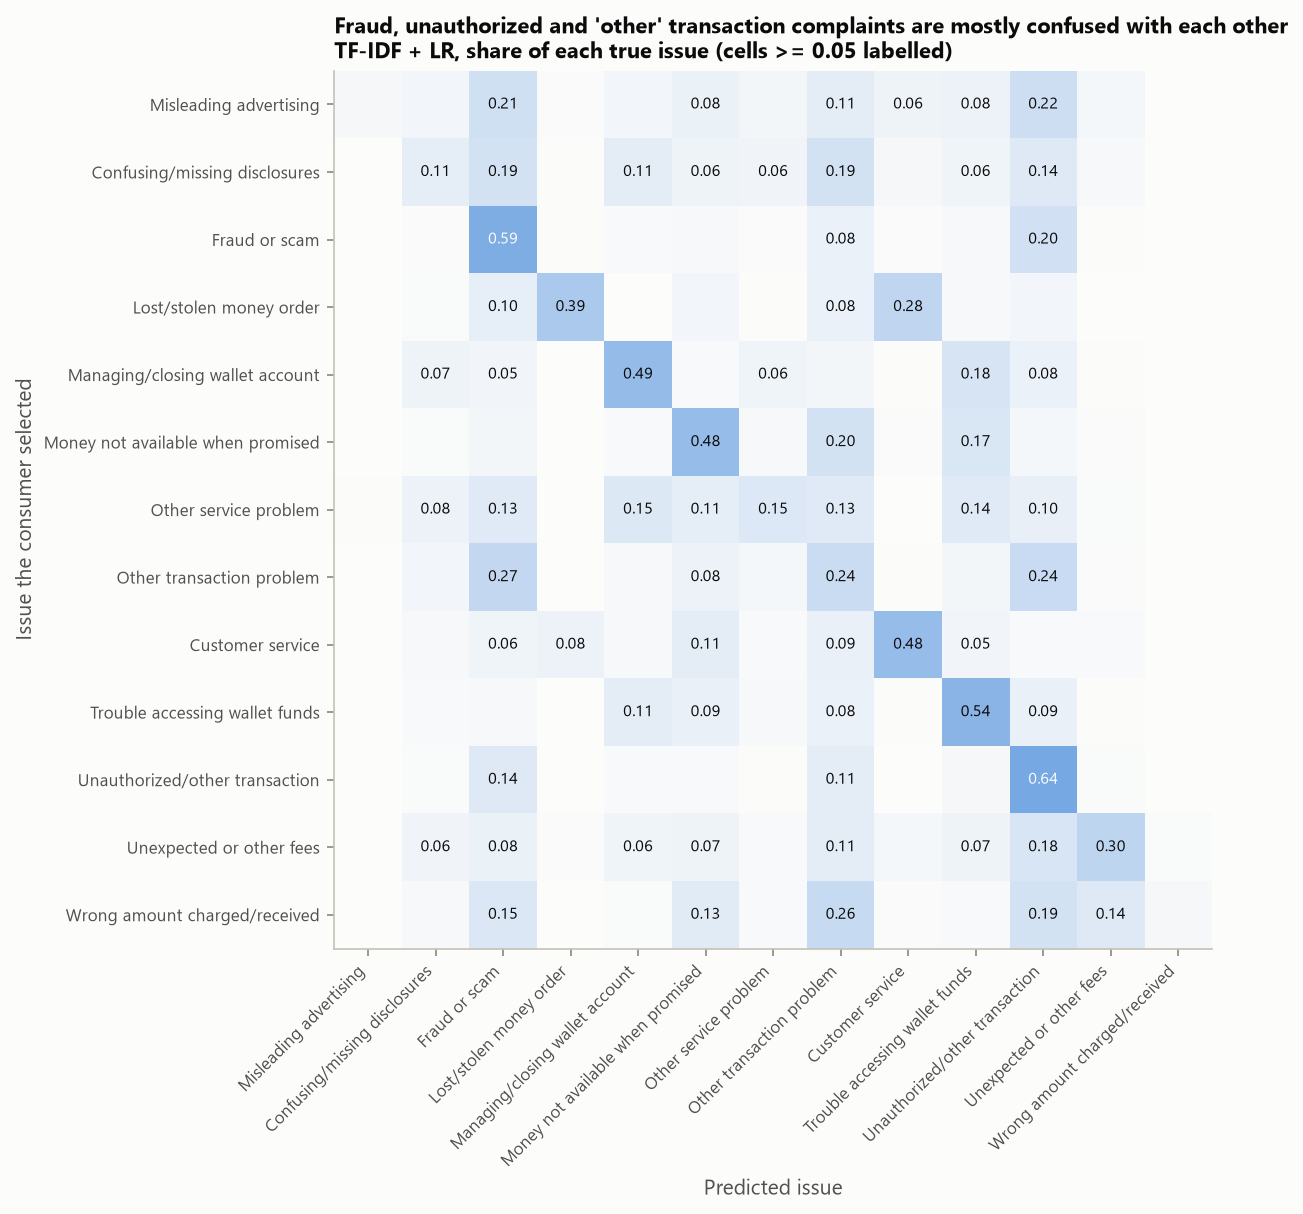

In [13]:
display(Image(FIG / '04_routing_confusion.png'))

## 4. Routing with a confidence threshold

A router does not have to decide every complaint. Sending only the most confident share automatically and
the rest to human triage trades coverage for accuracy: TF-IDF is right on 71% of its most confident quarter and
60% of its most confident half, against 44% overall.

In [14]:
rc = pd.read_csv(RES / 'routing_risk_coverage.csv')
rc[rc.coverage.round(2).isin([0.25, 0.5, 0.75, 1.0])].pivot(index='coverage', columns='model', values='accuracy')

model,DistilBERT (fine-tuned),TF-IDF + LR
coverage,,
0.25,0.650,0.710
0.50,0.528,0.600
0.75,0.449,0.514
1.00,0.384,0.442


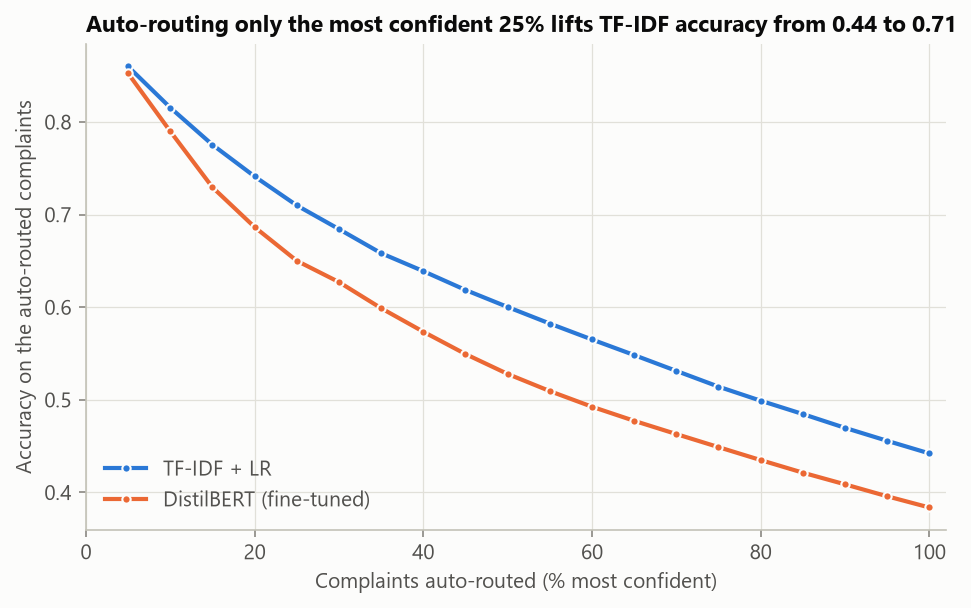

In [15]:
display(Image(FIG / '05_routing_risk_coverage.png'))

## 5. Emerging issues: topic bursts

One MiniLM-L6 embedding per near-duplicate group, k-means with 30 topics, and class-based TF-IDF labels
(BERTopic's weighting). Each topic's monthly share of all complaints is compared with its median monthly share
over the previous six months: a burst needs Benjamini-Hochberg q < 0.01 under a binomial model, at least twice the
baseline share, and at least 30 complaints. The median baseline matters: with the window's pooled share as the
baseline, the January 2025 flood drags every other topic's baseline down and the detector flags 142 topic-months,
122 of them in February-July 2025. The median baseline flags 38 (15 in those months); see the ablation table.

The 38 flagged topic-months include:

* **January 2025:** the Cash App template topic (23,807 complaints against 24 expected) and the Zelle
  "concerns ... CFPB lawsuit" topic (13,696 against 798, 17x). Both burst in distinct complaints too, not only in
  copies.
* **October 2025:** the Zelle topic again (883 against 73, 12x), mostly template copies (130 distinct groups), and
  an organic Chime dispute surge (158 against 56, 156 distinct groups).
* **November-December 2024:** restricted Robinhood accounts (93 against 21 in December, 4.4x).
* **April-May 2023:** PayPal account limitations (64 against 10 in April, 6.5x).

In [16]:
pd.read_csv(RES / 'topics.csv').sort_values('complaints', ascending=False)[['topic', 'top_terms', 'complaints', 'distinct_groups', 'top_issue', 'top_company']]

,topic,top_terms,complaints,distinct_groups,top_issue,top_company
4,4,"unfair, act, financial, cash app, cash, resolution",27482,945,Other transaction problem,"Block, Inc."
7,7,"zelle, concerns, cfpb, lawsuit, zelle failed, using zelle",16776,3954,Other transaction problem,"Early Warning Services, LLC"
26,26,"bank, money, fraud, account, america, bank america",5366,5067,Fraud or scam,"BANK OF AMERICA, NATIONAL ASSOCIATION"
1,1,"dispute, payment, credit, complaint, company, transaction",3024,2904,Fraud or scam,"Block, Inc."
2,2,"money, payment, sent, pay, company, card",2963,2869,Fraud or scam,"Block, Inc."
16,16,"chase, chase bank, bank, account, wire, money",2693,2639,Fraud or scam,JPMORGAN CHASE & CO.
17,17,"money, refund, moneygram, bank, western, western union",2682,2645,Other transaction problem,"WESTERN UNION COMPANY, THE"
21,21,"app, cash app, cash, account, cashapp, closed",2666,2652,Fraud or scam,"Block, Inc."
9,9,"account, money, closed, email, funds, access",2643,2623,Other transaction problem,"Block, Inc."
25,25,"funds, account, bank, transfer, square, financial",2550,2504,Other transaction problem,"Block, Inc."


In [17]:
bursts = pd.read_csv(RES / 'bursts.csv')
bursts[['month', 'topic', 'label', 'count', 'expected', 'ratio', 'distinct_groups', 'burst_in_distinct_groups']]

,month,topic,label,count,expected,ratio,distinct_groups,burst_in_distinct_groups
0,2021-11,27,"wells, fargo, wells fargo, fraud",36,15.464,2.328,34,True
1,2022-01,27,"wells, fargo, wells fargo, fraud",68,28.220,2.410,67,True
2,2022-02,27,"wells, fargo, wells fargo, fraud",54,26.758,2.018,51,False
3,2022-05,20,"paypal, account, paypal account, permanently",147,32.858,4.474,93,True
4,2022-07,7,"zelle, concerns, cfpb, lawsuit",30,8.748,3.429,30,True
5,2022-11,9,"account, money, closed, email",62,17.847,3.474,62,True
6,2022-11,13,"crypto, gemini, binance, com",58,21.405,2.710,57,True
7,2023-01,20,"paypal, account, paypal account, permanently",79,22.596,3.496,77,True
8,2023-01,3,"paypal, account, money, funds",50,24.616,2.031,30,False
9,2023-04,23,"paypal, account, limitation, paypal account",64,9.891,6.471,63,True


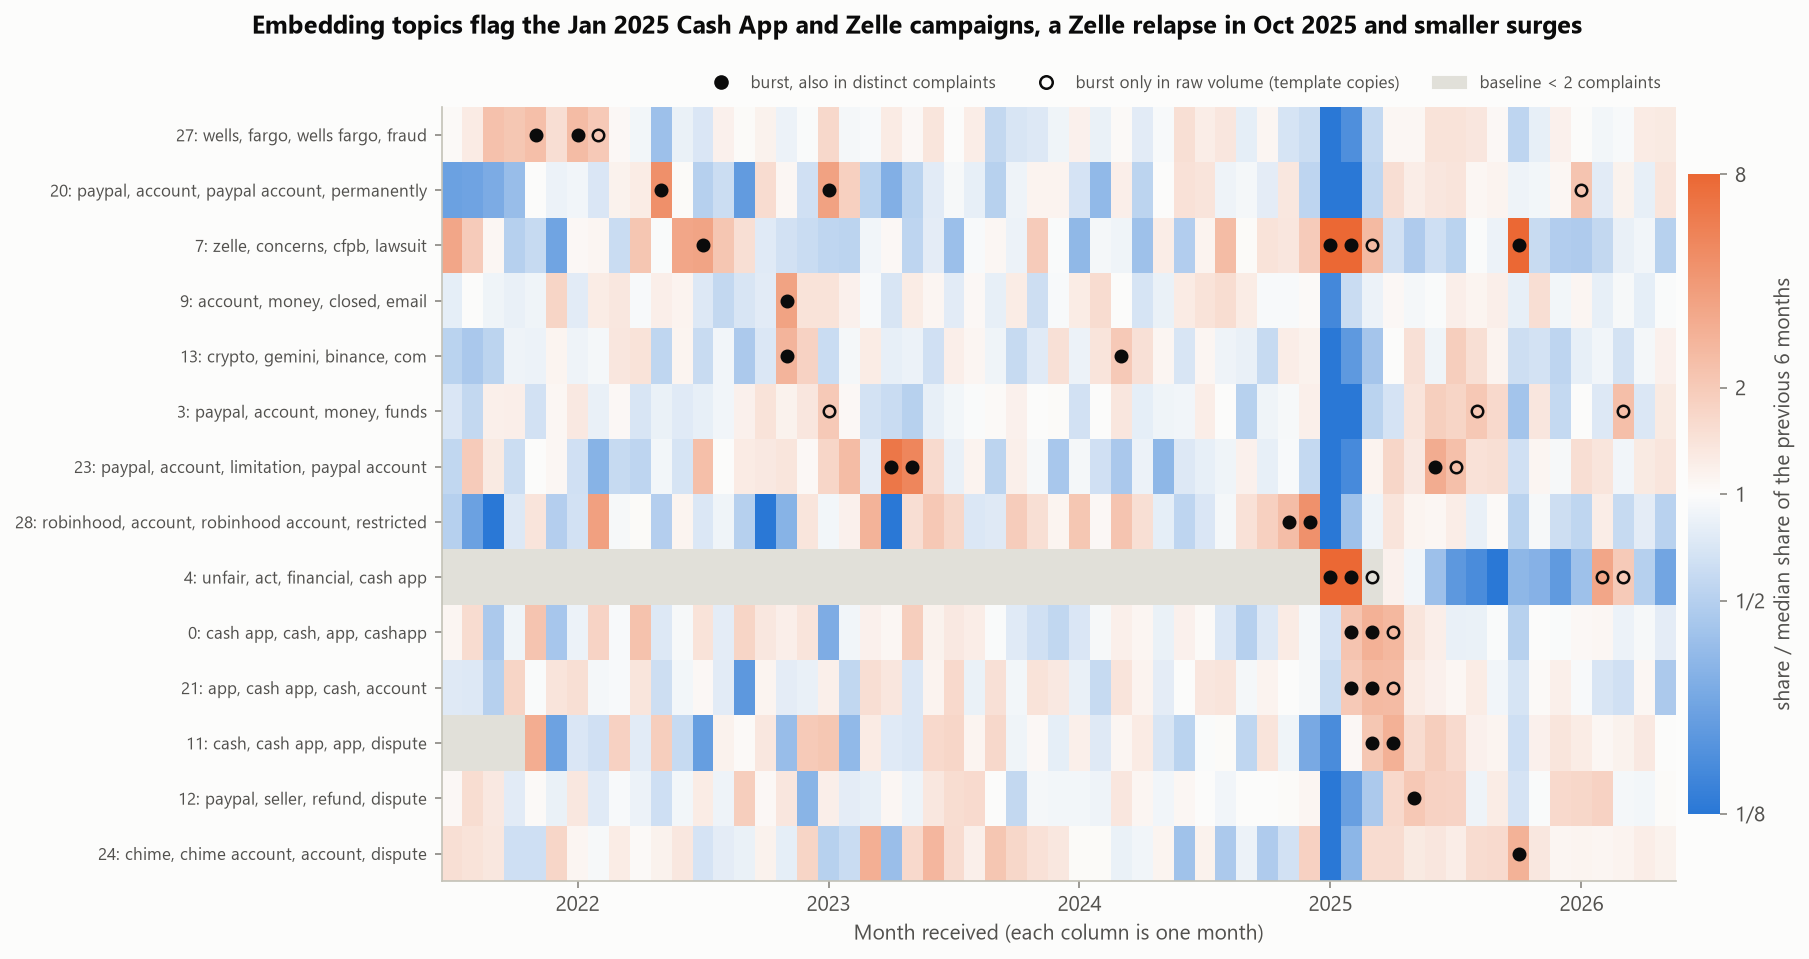

In [18]:
display(Image(FIG / '02_emerging_topic_bursts.png'))

In [19]:
pd.read_csv(RES / 'burst_baseline_ablation.csv')

,baseline,burst_topic_months,bursts_feb_to_jul_2025
0,median of monthly shares (used),38,15
1,pooled share of the window,142,122


### Baseline: the same detector on the CFPB issue labels

Run on the 17 issue labels instead of embedding topics, the detector flags 11 issue-months. January 2025 shows up only
as "Other transaction problem", which cannot tell the Cash App campaign from the Zelle one, and September to
November 2023 is flagged for "Trouble accessing funds in your mobile or digital wallet" only because that category
first appears in the data then (expected count below 1). Topics built from the text are the more useful unit.

In [20]:
pd.read_csv(RES / 'issue_label_bursts.csv')[['month', 'issue', 'count', 'expected', 'ratio']]

,month,issue,count,expected,ratio
0,2022-11,Confusing or missing disclosures,36,17.755,2.028
1,2023-01,Confusing or missing disclosures,61,18.457,3.305
2,2023-02,Confusing or missing disclosures,41,15.540,2.638
3,2022-05,"Managing, opening, or closing your mobile wallet account",165,66.286,2.489
4,2025-01,Other transaction problem,36925,7512.681,4.915
5,2025-02,Other transaction problem,3130,875.739,3.574
6,2025-03,Other transaction problem,920,404.046,2.277
7,2025-10,Other transaction problem,1256,599.908,2.094
8,2023-09,Trouble accessing funds in your mobile or digital wallet,79,0.528,149.586
9,2023-10,Trouble accessing funds in your mobile or digital wallet,83,0.616,134.840


### Injection-recovery: does the detector find surges it should find?

200 random quiet topic-months (2022 onward) received synthetic extra complaints, from +50% to +500% of the
topic's expected count, and the detector was re-run each time. A surge of +200% is flagged 89% of the time and
+300% 95%; +100% (exactly the doubling rule) only 29%. Small topics (fewer than 15 expected complaints a month)
need larger surges because of the 30-complaint minimum.

In [21]:
inj = pd.read_csv(RES / 'burst_injection.csv')
inj.pivot_table(index='multiplier', values=['detected', 'other_new_bursts'], aggfunc='mean')

,detected,other_new_bursts
multiplier,,
0.5,0.070,-0.095
1.0,0.290,-0.120
1.5,0.735,-0.155
2.0,0.885,-0.170
3.0,0.950,-0.145
5.0,1.000,-0.040


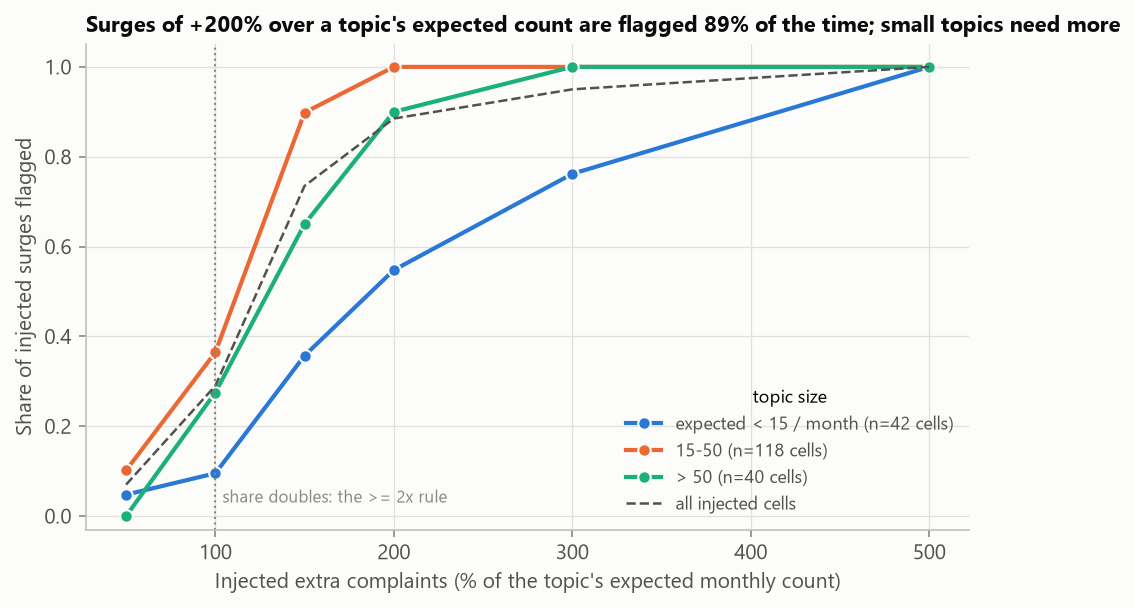

In [22]:
display(Image(FIG / '08_burst_injection_recovery.png'))

## 6. Similar-case search

Queries are 1,000 random deduplicated 2025-26 complaints; the corpus is the 17,707 deduplicated 2023-24
complaints. A retrieved case counts as relevant when it has the query's issue, a noisy proxy given the routing
results. Random retrieval would score 0.177.

* MiniLM-L6 and BGE-small embeddings (FAISS exact search) both reach P@10 0.33-0.34, +0.06 over TF-IDF (Holm
  p < 0.001). The two embedders are indistinguishable.
* Reranking the BGE-small top 50 with the MS MARCO MiniLM cross-encoder raises P@1 from 0.353 to 0.393
  (p = 0.029, but 0.087 after Holm correction) and leaves P@10 unchanged. A web-search cross-encoder is not a
  complaint-similarity model.

In [23]:
display(pd.read_csv(RES / 'search_results.csv'))
pd.read_csv(RES / 'search_significance.csv')

,method,p@1,p@1_ci_low,p@1_ci_high,p@5,p@5_ci_low,p@5_ci_high,p@10,p@10_ci_low,p@10_ci_high,same_subproduct_p@10
0,Random (label prior),0.177,0.170,0.184,0.177,0.169,0.184,0.177,0.169,0.184,0.279
1,TF-IDF,0.287,0.261,0.316,0.275,0.258,0.291,0.276,0.263,0.290,0.438
2,MiniLM-L6,0.343,0.313,0.373,0.345,0.326,0.364,0.335,0.318,0.353,0.491
3,BGE-small,0.353,0.323,0.382,0.350,0.331,0.370,0.334,0.317,0.350,0.477
4,BGE-small + cross-encoder,0.393,0.362,0.423,0.356,0.337,0.375,0.328,0.311,0.344,0.499


,baseline,system,metric,mean_diff,ci_low,ci_high,p_value,p_holm
0,TF-IDF,MiniLM-L6,p@10,0.059,0.047,0.072,1.000e-04,6.000e-04
1,TF-IDF,BGE-small,p@10,0.058,0.046,0.070,1.000e-04,6.000e-04
2,MiniLM-L6,BGE-small,p@10,-0.002,-0.012,0.009,7.737e-01,7.737e-01
3,BGE-small,BGE-small + cross-encoder,p@10,-0.006,-0.015,0.004,2.564e-01,5.127e-01
4,Random (label prior),TF-IDF,p@10,0.099,0.087,0.111,1.000e-04,6.000e-04
5,BGE-small,BGE-small + cross-encoder,p@1,0.040,0.004,0.075,2.900e-02,8.700e-02


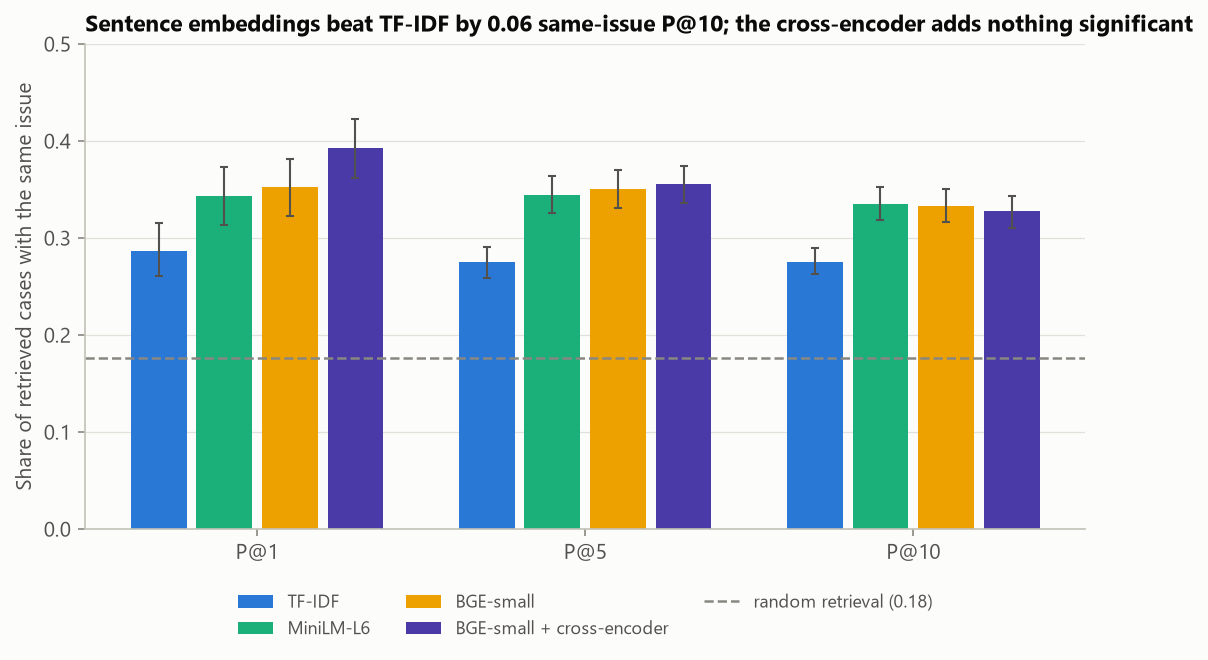

In [24]:
display(Image(FIG / '07_similar_case_precision.png'))

In [25]:
pd.read_csv(RES / 'search_examples.csv')[['query_issue', 'query_start', 'rank', 'match_issue', 'match_start']]

,query_issue,query_start,rank,match_issue,match_start
0,Fraud or scam,I noticed in 2012 that I was getting multiple cash cards for Cash app in my parents ma...,1,Fraud or scam,my data was in breach. then i receive a cashapp card with my name on back but not my h...
1,Fraud or scam,I noticed in 2012 that I was getting multiple cash cards for Cash app in my parents ma...,2,Unauthorized transactions or other transaction problem,/ at about I started getting text messages saying my Cash App information has been cha...
2,Fraud or scam,I noticed in 2012 that I was getting multiple cash cards for Cash app in my parents ma...,3,Fraud or scam,I've had a cash app account for years with my legal name and banking information attac...
3,Unauthorized transactions or other transaction problem,I requested that PayPal : - * * Provide provisional ( temporary ) credits * * immediat...,1,Unauthorized transactions or other transaction problem,I have a paypal claim for $270.00 with a banking service ( seller 's bank ) . I have p...
4,Unauthorized transactions or other transaction problem,I requested that PayPal : - * * Provide provisional ( temporary ) credits * * immediat...,2,Unauthorized transactions or other transaction problem,"On /24, I contacted PayPal to advise that I did not receive my entire order from that ..."
5,Unauthorized transactions or other transaction problem,I requested that PayPal : - * * Provide provisional ( temporary ) credits * * immediat...,3,Unauthorized transactions or other transaction problem,"I opened a dispute on PayPa CASE ID , reporting an unauthorized transaction. Exactly f..."
6,Other transaction problem,I am writing to formerly express my concerns regarding Zelle handling of disputes. Zel...,1,Other transaction problem,"Zelle transaction. . Spoke with the fraud departments at Zelle, , FBI, local consumer ..."
7,Other transaction problem,I am writing to formerly express my concerns regarding Zelle handling of disputes. Zel...,2,Unauthorized transactions or other transaction problem,I tried to complete a financial transaction via Zelle using my account on / . Unfortun...
8,Other transaction problem,I am writing to formerly express my concerns regarding Zelle handling of disputes. Zel...,3,Other transaction problem,"Dear Consumer Financial Protection Bureau, I am filing this complaint regarding the un..."


## 7. Entity extraction spot check (spaCy)

`en_core_web_sm` was run on 400 random test narratives and compared with structure the CFPB itself provides:

* **MONEY works.** The CFPB keeps dollar amounts and wraps them in braces (`{$450.00}`); spaCy recovers all of
  them and returns no other amounts.
* **DATE does not.** 46% of narratives contain a redacted date (`XX/XX/XXXX`); spaCy tags none of them. Its 0.86
  DATE entities per narrative are relative phrases such as "the same day".
* **ORG is noisy.** 45% of ORG entities are redaction marks (`XXXX`), and in the 269 narratives that name their
  company by a known brand, an ORG entity names it only 45% of the time.

This is a capability check on 400 documents, not a benchmark: there is no hand-labelled gold standard.

In [26]:
display(pd.read_csv(RES / 'entity_spotcheck.csv'))
display(pd.read_csv(RES / 'entity_label_counts.csv'))
pd.read_csv(RES / 'entity_examples.csv')

,check,value
0,documents checked,400.000
1,ORG entities per document (mean),4.253
2,ORG: share of ORG entities that are only a redaction mark (XXXX),0.452
3,MONEY: share of brace amounts recovered,1.000
4,MONEY: share of extracted amounts that match a brace amount,1.000
5,DATE: share of documents whose text contains a redacted date (XX/XX/XXXX),0.458
6,DATE: DATE entities per document (mean),0.860
7,DATE: share of DATE entities that are redacted dates (XX/XX/XXXX),0.000
8,documents naming their company (alias list),269.000
9,ORG: share of those where an ORG entity names the company,0.446


,label,count
0,ORG,1701
1,MONEY,424
2,DATE,344


,complaint_id,company,entities
0,11402258,U.S. BANCORP,MONEY: 2800.00; MONEY: 1100.00; MONEY: 1400.00; MONEY: 130.00; MONEY: 120.00; MONEY: 5...
1,15722947,UMB FINANCIAL CORPORATION,ORG: ACH; ORG: XXXX; ORG: XXXX; ORG: UMB Bank; ORG: XXXX; DATE: the same day; ORG: ACH...
2,13111361,WELLS FARGO & COMPANY,DATE: less then a month; ORG: Wells Fargo; ORG: XXXX; ORG: Wells Fargo; ORG: XXXX; ORG...
3,18038538,"Paypal Holdings, Inc",ORG: XXXX; ORG: XXXX; ORG: XXXX; DATE: 180-day; ORG: XXXX; ORG: XXXX; DATE: 180-day
4,11856580,"Block, Inc.",NaN


## Takeaways for a complaint operations team

1. **Deduplicate before anything else.** Over half of 2025-26 complaints were template copies. Without grouping,
   evaluation numbers swing by 0.06 macro-F1 and a burst detector chases campaigns for months.
2. **Evaluate routers on future months.** Random cross-validation overstated macro-F1 by 0.045.
3. **A linear TF-IDF model is a strong, cheap router** for long, noisy narratives; within a small GPU budget the
   fine-tuned transformer did not beat it. Use a confidence threshold and send the rest to triage.
4. **Monitor topics, not the intake taxonomy.** Text topics separate campaigns that share one issue label, and a
   median baseline keeps one flood month from drowning the next six.
5. **Use embeddings for similar-case search;** an off-the-shelf web-search reranker is not worth its latency here.